# *********************Social Media Engagement Analytics Using Python********************* #

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## ❖	Task 1 — Data Import & Setup

In [2]:
#Import CSV using Pandas
df_rawdata=pd.read_csv(r"C:\Users\anitv\Downloads\social_media_engagement_5000.csv")
df=df_rawdata.copy()  # work on a copy so the raw data stays untouched
print(df)
print("Shape:", df.shape)


      user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  Female     Brazil   496713     image       fitness   
1       10860  33.0    Male     Brazil   157326      reel          food   
2       86820  32.0  Female         UK   109864      text          food   
3       64886  51.0   Other     France   848877      text       fitness   
4       16265  34.0   Other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count   posted_at  \
0      7011.0     

In [3]:
#Check data types
print("\n",df.dtypes,"\n")

df.info()
print("\n",df.columns)



 user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object 

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         50

In [4]:
#Convert data type
df["posted_at"] = pd.to_datetime(df["posted_at"],dayfirst=True,errors="coerce")
print("\nDatatype of posted_at column:",df["posted_at"].dtype)
df


Datatype of posted_at column: datetime64[us]


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [5]:
# Using NumPy arrays for basic array operations

# Convert comments column into a NumPy array
impression_count_array = df["impression_count"].to_numpy()

# Basic array operations
print("\nFirst five comments:", impression_count_array[:5])
print("Average comments:", np.mean(impression_count_array))
print("Maximum comments:", np.max(impression_count_array))
print("Minimum comments:", np.min(impression_count_array))
print("Total comments:", np.sum(impression_count_array))


First five comments: [44650 80216 44858 70455  6019]
Average comments: 50013.7328
Maximum comments: 99995
Minimum comments: 105
Total comments: 250068664


## ❖	Task 2 — Data Cleaning

### Cleaning Missing Data


In [6]:
# Detect missing values (isnull(), isna())

# Check missing values in each column using isnull()
print("\nMissing values found using isnull()\n")
print(df.isnull().sum())

# Check missing values using isna()
print("\nMissing values found using isna()\n")
print(df.isna().sum())

# Find the total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())


Missing values found using isnull()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Missing values found using isna()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
d

In [7]:
# Handle missing values using: dropna(), fillna(), median/mode, forward/backward-fill

# For numeric columns fill the missing with the median
for col in ["age", "likes", "comments", "shares"]:
    df[col] = df[col].fillna(df[col].median())

# For categorical columns fill the missing value with Unknown
for col in ["gender", "sentiment"]:
    df[col] = df[col].fillna("Unknown")

print("Number of missing values:", df.isnull().sum().sum())


Number of missing values: 0


In [8]:
# Duplicate Handling --- duplicate checking was based on complete rows

# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

print("Duplicates remaining:", df.duplicated().sum())

Number of duplicate rows: 0
Duplicates remaining: 0


In [9]:
# Data Formatting

# Check data types. Already datatype of posted_at is formatted to datetime.
print(df.dtypes)

# Convert post_id and user_id to string
df["post_id"] = df["post_id"].astype("string")
df["user_id"] = df["user_id"].astype("string")

# Convert engagement columns to numeric
df["likes"] = df["likes"].astype(int)
df["comments"] = df["comments"].astype(int)
df["shares"] =df["shares"].astype(int)
df["age"]=df["age"].astype(int)

# Check updated data types
print("\nData types after formatting\n",df.dtypes)

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

Data types after formatting
 user_id                     string
age                          int64
gender                         str
country                        str
post_id                     string
post_type                      str
post_category                  str
likes                        int64
comments   

In [10]:
# Standardize categories : trim spaces and fix case

for col in ["post_type", "post_category", "device_type", "sentiment"]:
    df[col] = df[col].str.strip().str.lower()
    
df["gender"] = df["gender"].str.strip().str.title()
df["country"] = df["country"].str.strip()

for col in ["gender", "sentiment", "post_type", "device_type"]:
    print(col, ":", df[col].unique())

gender : <ArrowStringArray>
['Female', 'Male', 'Other', 'Unknown']
Length: 4, dtype: str
sentiment : <ArrowStringArray>
['negative', 'positive', 'neutral', 'unknown']
Length: 4, dtype: str
post_type : <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
device_type : <ArrowStringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str


In [11]:
# Unrealistic-value checks
num_cols = ["age", "likes", "comments", "shares", "watch_time_sec", "impression_count", "follower_count"]
print("Negative values:", int((df[num_cols] < 0).sum().sum()))
print("Age outside 13-100:", int((~df["age"].between(13, 100)).sum()))
print("Likes greater than impressions:", int((df["likes"] > df["impression_count"]).sum()))
print("Likes+comments+shares greater than impressions:",
     ((df["likes"] + df["comments"] + df["shares"]) > df["impression_count"]).sum())
print("Rows with engagement_rate > 100:", int((df["engagement_rate"] > 100).sum()))
print("Rows with engagement_rate > 10: ", int((df["engagement_rate"] > 10).sum()))

# Likes can't exceed impressions, so any extra likes are reduced to the impression count.

df["likes_reduced"] = df["likes"] > df["impression_count"]
df["likes"] = np.minimum(df["likes"], df["impression_count"])
print("Likes corrected:", int(df["likes_reduced"].sum()))

Negative values: 0
Age outside 13-100: 0
Likes greater than impressions: 464
Likes+comments+shares greater than impressions: 600
Rows with engagement_rate > 100: 3
Rows with engagement_rate > 10:  68
Likes corrected: 464


In [12]:
#Feature Cleaning

#Extract hashtag count

# Hashtag count from the space-separated hashtags column
df["hashtags"] = df["hashtags"].fillna("").str.strip()
def count(x):
    if isinstance(x, list):
        return len(x)
    if isinstance(x, str):
        return len(x.split())
    return 0
df["hashtag_count"] = df["hashtags"].apply(count)
print("      Hashtag count\n")
print(df["hashtag_count"])

      Hashtag count

0       3
1       1
2       1
3       3
4       1
       ..
4995    2
4996    2
4997    2
4998    3
4999    3
Name: hashtag_count, Length: 5000, dtype: int64


In [13]:
# Clean sentiment labels

# Sentiment labels are already clean (positive / neutral / negative / unknown)
print(df["sentiment"].value_counts())

sentiment
positive    2363
neutral     1527
negative     960
unknown      150
Name: count, dtype: int64


## ❖	Task 3 — Data Exploration using Pandas

In [14]:
#View dataset structure using head(), tail(), shape, and columns

# 1. Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# 2. Display the last 5 rows
print("\nLast 5 rows of the dataset:")
display(df.tail())

# 3. Display the number of rows and columns
print("\nDataset shape (rows, columns):")
print(df.shape)

# 4. Display all column names
print("\nColumn names:")
print(df.columns)


First 5 rows of the dataset:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,likes_reduced,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,...,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,False,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,...,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,False,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,...,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,False,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,False,3
4,16265,34,Other,UK,449706,image,fitness,6019,2735,1300,...,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,True,1



Last 5 rows of the dataset:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,likes_reduced,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,...,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,False,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,...,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,False,2
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,...,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,False,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,...,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,False,3
4999,73400,54,Other,Japan,712252,text,travel,14234,503,1798,...,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,True,3



Dataset shape (rows, columns):
(5000, 21)

Column names:
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'likes_reduced', 'hashtag_count'],
      dtype='str')


In [15]:
#Check data types and info with info() and dtypes.

# Display dataset information
df.info()

# Check data types of all columns
print(df.dtypes)


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   string        
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   string        
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [16]:
#Generate summary statistics using describe().

# Summary statistics for numerical columns
display(df.describe())

# Summary statistics for numerical and categorical columns
display(df.describe(include="all"))

,age,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,38.440400,9457.719000,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,13.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,26.000000,4561.250000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,38.000000,9382.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,51.000000,14155.750000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,64.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,14.687151,5667.384439,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,likes_reduced,hashtag_count
count,5000,5000.000000,5000,5000,5000,5000,5000,5000.000000,5000.000000,5000.0000,...,5000.000000,5000,5000.000000,5000,5000,5000,5000,5000.000000,5000,5000.000000
unique,4862,NaN,4,10,4991,4,8,NaN,NaN,NaN,...,NaN,NaN,NaN,2,3,4,761,NaN,2,NaN
top,74925,NaN,Male,India,671719,reel,fitness,NaN,NaN,NaN,...,NaN,NaN,NaN,False,mobile,positive,#tech,NaN,False,NaN
freq,3,NaN,1699,535,2,1283,675,NaN,NaN,NaN,...,NaN,NaN,NaN,4517,1684,2363,201,NaN,4536,NaN
mean,NaN,38.440400,NaN,NaN,NaN,NaN,NaN,9457.719000,1502.039800,1002.9106,...,50013.732800,2022-12-28 13:21:30.240000,393698.224800,NaN,NaN,NaN,NaN,0.964356,NaN,1.998600
min,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,10.000000,0.000000,0.0000,...,105.000000,2022-01-01 00:00:00,87.000000,NaN,NaN,NaN,NaN,0.006363,NaN,1.000000
25%,NaN,26.000000,NaN,NaN,NaN,NaN,NaN,4561.250000,792.000000,511.0000,...,24988.250000,2022-07-03 18:00:00,194480.000000,NaN,NaN,NaN,NaN,0.145781,NaN,1.000000
50%,NaN,38.000000,NaN,NaN,NaN,NaN,NaN,9382.000000,1497.000000,1012.0000,...,49934.500000,2022-12-27 00:00:00,388982.000000,NaN,NaN,NaN,NaN,0.253896,NaN,2.000000
75%,NaN,51.000000,NaN,NaN,NaN,NaN,NaN,14155.750000,2235.250000,1483.0000,...,74662.250000,2023-06-28 00:00:00,589744.250000,NaN,NaN,NaN,NaN,0.504794,NaN,3.000000
max,NaN,64.000000,NaN,NaN,NaN,NaN,NaN,19998.000000,2999.000000,1999.0000,...,99995.000000,2023-12-31 00:00:00,799533.000000,NaN,NaN,NaN,NaN,191.504348,NaN,3.000000


In [17]:
#Create a correlation matrix for numeric fields.
corr = df.select_dtypes(include="number").corr()
print(corr)
corr = df.select_dtypes(include="number").corr().round(2)
print(corr)

                       age     likes  comments    shares  watch_time_sec  \
age               1.000000 -0.031627 -0.007284  0.013871        0.005542   
likes            -0.031627  1.000000 -0.013195 -0.001150        0.002956   
comments         -0.007284 -0.013195  1.000000  0.006142       -0.016351   
shares            0.013871 -0.001150  0.006142  1.000000        0.014658   
watch_time_sec    0.005542  0.002956 -0.016351  0.014658        1.000000   
impression_count  0.013322  0.187378 -0.009395 -0.005204       -0.004335   
follower_count   -0.024894 -0.027476 -0.011733 -0.010783        0.002761   
engagement_rate   0.008039 -0.146343  0.000051  0.021724       -0.001148   
hashtag_count     0.007173 -0.002146 -0.015230  0.013379       -0.023301   

                  impression_count  follower_count  engagement_rate  \
age                       0.013322       -0.024894         0.008039   
likes                     0.187378       -0.027476        -0.146343   
comments                 -

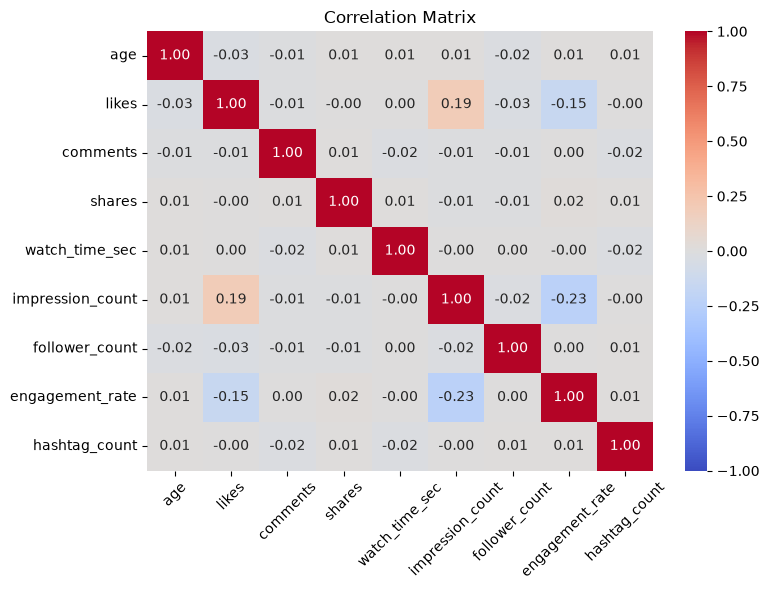

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
#Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country)
display(df.groupby("post_type")[["likes", "comments", "shares"]].mean().round(0).astype(int))
display(df.groupby("country")["impression_count"].mean().round(0).astype(int).sort_values(ascending=False))


,likes,comments,shares
post_type,,,
image,9448,1525,1019
reel,9514,1504,982
text,9416,1499,1014
video,9452,1479,997


country
India        52462
France       51728
USA          51264
UK           51119
Japan        49616
Brazil       49193
UAE          48928
Canada       48703
Germany      48605
Australia    48346
Name: impression_count, dtype: int64

## ❖	Task 4 — Data Wrangling 

In [20]:
#Use merge, concat, or join if combining DataFrames

# Since the dataset was provided as a single DataFrame, so merging,concat or joining was not required

In [21]:
# New fields
df["interactions"] = df["likes"] + df["comments"] + df["shares"]
df["engagement_score"] = df["interactions"] / df["impression_count"] * 100        # % of impressions that interacted
df["log_impressions"] = np.log1p(df["impression_count"])
df["log_followers"] = np.log1p(df["follower_count"])
df["log_engagement_rate"] = np.log1p(df["engagement_rate"])
df["post_month"] = df["posted_at"].dt.to_period("M").astype(str)
df["post_weekday"] = df["posted_at"].dt.day_name()
df["age_group"] = pd.cut(df["age"], bins=[12, 17, 24, 34, 44, 54, 64], labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55-64"])
df[["interactions", "engagement_score", "hashtag_count", "log_impressions", "age_group"]].head()

,interactions,engagement_score,hashtag_count,log_impressions,age_group
0,8522,19.086226,3,10.706632,35-44
1,16163,20.149347,1,11.292491,25-34
2,6161,13.734451,1,10.711280,25-34
3,7482,10.619544,3,11.162744,45-54
4,10054,167.037714,1,8.702843,25-34


In [22]:
# groupby summaries by post_type, country, and sentiment.

#groupby summaries by post_type
print("\nGroupby summaries by post_type")
display(
    df.groupby("post_type")[
        ["likes", "comments", "shares", "engagement_score","impression_count"]
    ].mean().round(0)
)
#groupby summaries by country
print("\nGroupby summaries by country")
display(
    df.groupby("country")[["likes", "comments", "shares", "engagement_score","impression_count"]]
    .mean()
    .round(0)    
)
#groupby summaries by sentiment
print("\nGroupby summaries by sentiment")
display(
    df.groupby("sentiment")[
        ["likes", "comments", "shares", "engagement_score","impression_count"]
    ].mean().round(0)
)


Groupby summaries by post_type


,likes,comments,shares,engagement_score,impression_count
post_type,,,,,
image,9448.0,1525.0,1019.0,49.0,49727.0
reel,9514.0,1504.0,982.0,47.0,50463.0
text,9416.0,1499.0,1014.0,52.0,49987.0
video,9452.0,1479.0,997.0,51.0,49862.0



Groupby summaries by country


,likes,comments,shares,engagement_score,impression_count
country,,,,,
Australia,9441.0,1486.0,1030.0,59.0,48346.0
Brazil,9303.0,1490.0,1009.0,59.0,49193.0
Canada,9426.0,1547.0,996.0,48.0,48703.0
France,9571.0,1479.0,1052.0,55.0,51728.0
Germany,9633.0,1532.0,973.0,44.0,48605.0
India,9507.0,1495.0,1035.0,43.0,52462.0
Japan,9460.0,1530.0,959.0,49.0,49616.0
UAE,9289.0,1541.0,989.0,53.0,48928.0
UK,9389.0,1463.0,986.0,47.0,51119.0



Groupby summaries by sentiment


,likes,comments,shares,engagement_score,impression_count
sentiment,,,,,
negative,9379.0,1516.0,1007.0,52.0,50192.0
neutral,9289.0,1528.0,997.0,52.0,49516.0
positive,9539.0,1482.0,1002.0,49.0,49986.0
unknown,10396.0,1453.0,1056.0,35.0,54375.0


## ❖	Task 5 — Statistical Analysis 

In [28]:
# Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:

# Mean, median, mode
# Standard deviation, variance
# Percentiles
#(Optional) Skewness and kurtosis

stat_cols = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]
stats = pd.DataFrame({
    "mean": df[stat_cols].mean(),
    "median": df[stat_cols].median(),
    "mode": [df[c].mode()[0] for c in stat_cols],
    "std": df[stat_cols].std(),
    "variance": df[stat_cols].var(),
    "p25": df[stat_cols].quantile(0.25),
    "p50": df[stat_cols].quantile(0.50),
    "p75": df[stat_cols].quantile(0.75),
    "p90": df[stat_cols].quantile(0.90),
    "p99": df[stat_cols].quantile(0.99),
    "skewness": df[stat_cols].skew(),
    "kurtosis": df[stat_cols].kurt(),
})
stats.round(3)


,mean,median,mode,std,variance,p25,p50,p75,p90,p99,skewness,kurtosis
likes,9457.719,9382.000,10105.000,5667.384,3.211925e+07,4561.250,9382.000,14155.750,17565.100,19832.060,0.120,-1.124
comments,1502.040,1497.000,1497.000,856.393,7.334095e+05,792.000,1497.000,2235.250,2695.100,2975.010,0.004,-1.144
shares,1002.911,1012.000,1012.000,570.855,3.258757e+05,511.000,1012.000,1483.000,1795.100,1983.000,-0.015,-1.147
watch_time_sec,4014.503,4034.500,916.000,2308.096,5.327309e+06,2017.750,4034.500,6020.250,7212.100,7924.040,-0.018,-1.196
engagement_rate,0.964,0.254,0.006,5.318,2.828100e+01,0.146,0.254,0.505,1.201,13.672,18.781,482.992
follower_count,393698.225,388982.000,497502.000,230927.885,5.332769e+10,194480.000,388982.000,589744.250,717755.900,792524.700,0.041,-1.189


## ❖	Task 6 — Data Visualization 

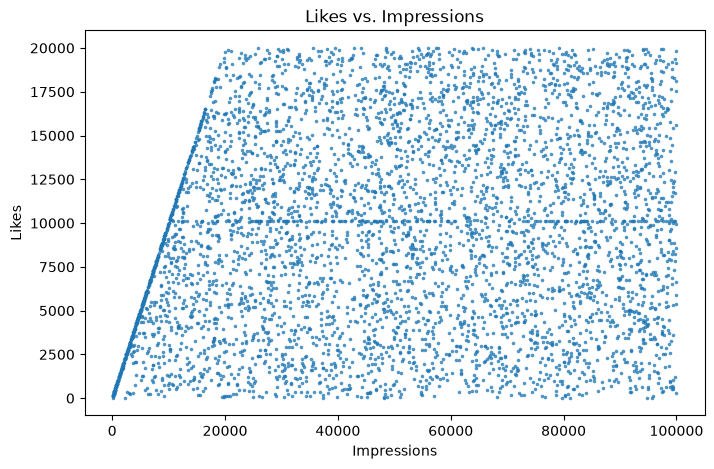

In [42]:
# Matplotlib

# Scatter: likes vs impressions

plt.figure(figsize=(8, 5))
plt.scatter(df["impression_count"], df["likes"], alpha=0.75,s=5,linewidths=0.3)
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs. Impressions")
plt.show()

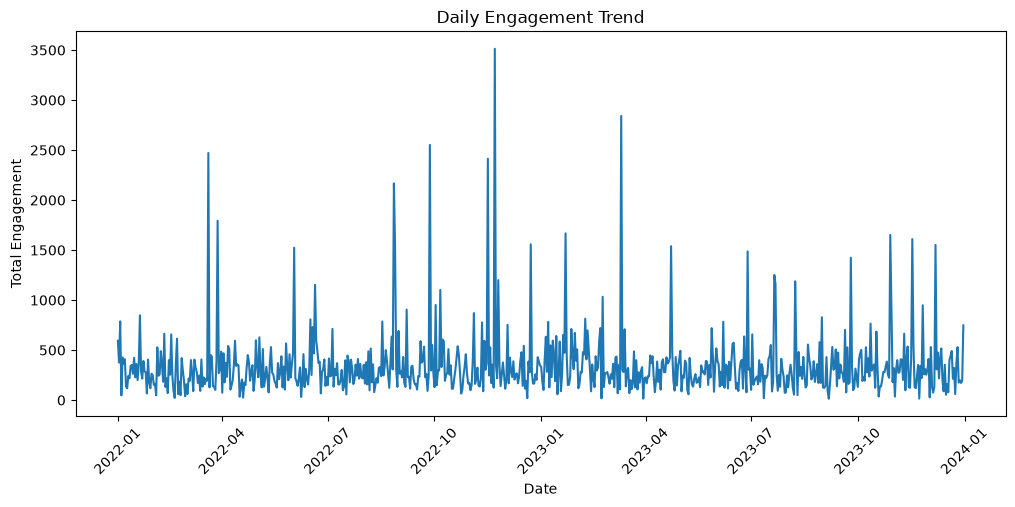

In [45]:
#Line: daily engagement trend

daily_engagement = (df.groupby(df["posted_at"].dt.date)["engagement_score"].sum())
plt.figure(figsize=(12, 5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.xlabel("Date")
plt.ylabel("Total Engagement")
plt.title("Daily Engagement Trend")
plt.xticks(rotation=45)
plt.show()

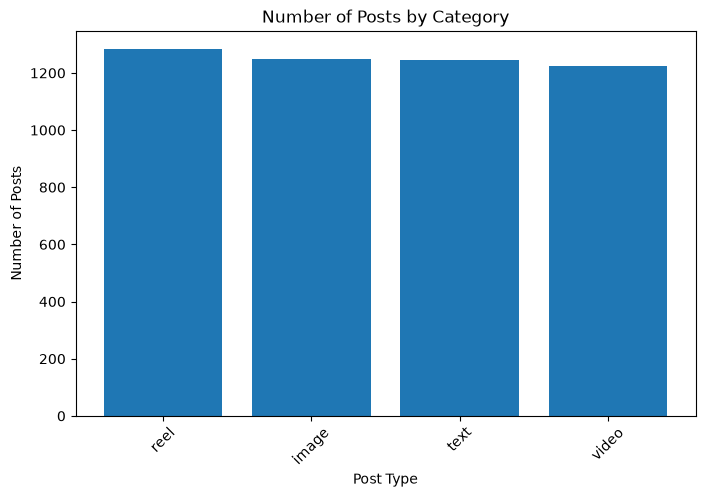

In [46]:
#Bar: posts by category
post_counts = df["post_type"].value_counts()
plt.figure(figsize=(8, 5),)
plt.bar(post_counts.index, post_counts.values)
plt.xlabel("Post Type")
plt.ylabel("Number of Posts")
plt.title("Number of Posts by Category")
plt.xticks(rotation=45)
plt.show()

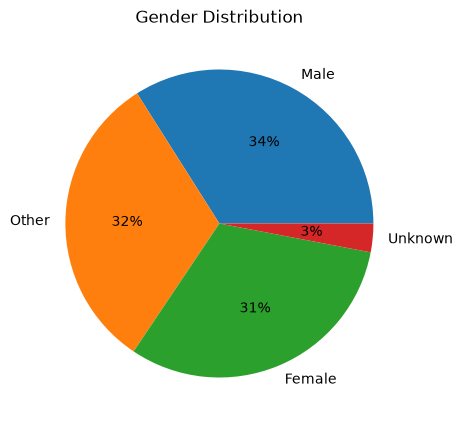

In [50]:
#Pie: gender distribution
gender_counts = df["gender"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(gender_counts.values,labels=gender_counts.index,autopct="%1.0f%%")
plt.title("Gender Distribution")
plt.show()

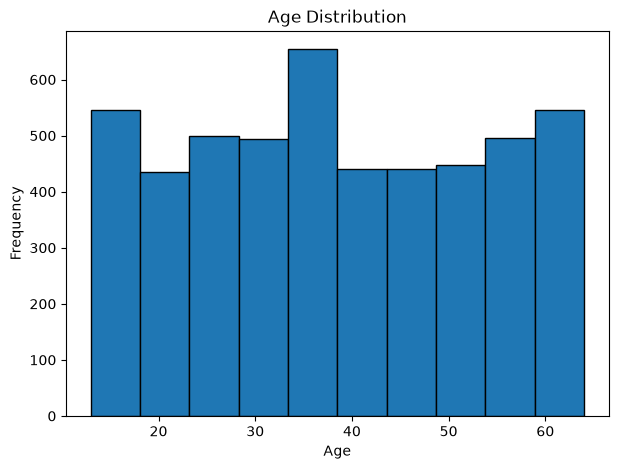

In [52]:
#Histogram: age
plt.figure(figsize=(7, 5))
plt.hist(df["age"].dropna(), bins=10, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.show()

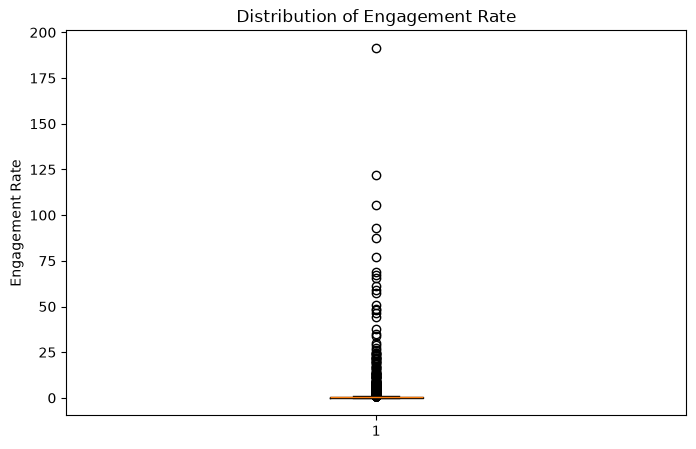

In [53]:
#Box: engagement rate
plt.figure(figsize=(8, 5))
plt.boxplot(df["engagement_rate"].dropna())
plt.ylabel("Engagement Rate")
plt.title("Distribution of Engagement Rate")
plt.show()

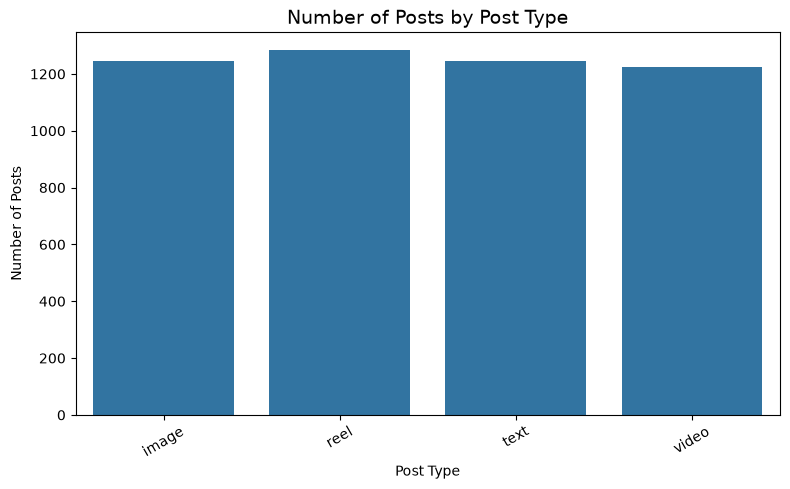

In [54]:
#Seaborn

#Count plot: post type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="post_type")
plt.title("Number of Posts by Post Type", fontsize=14)
plt.xlabel("Post Type")
plt.ylabel("Number of Posts")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


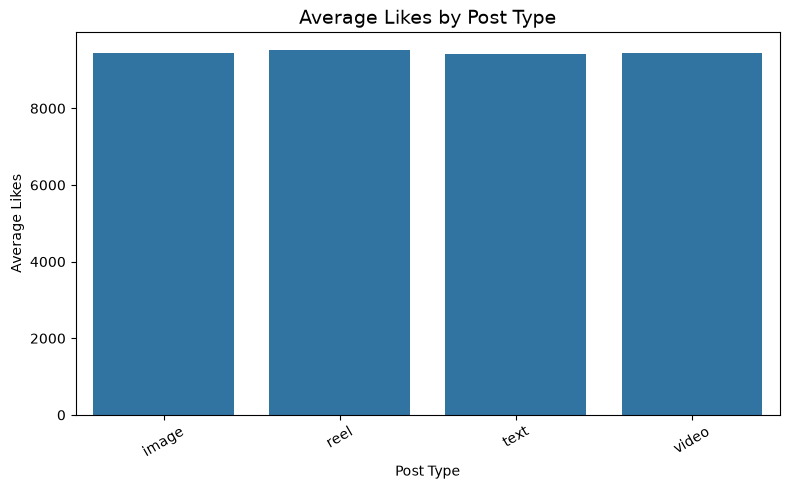

In [58]:
#Bar plot: avg likes by category
plt.figure(figsize=(8, 5))
sns.barplot(data=df,x="post_type",y="likes",errorbar=None)
plt.title("Average Likes by Post Type", fontsize=14)
plt.xlabel("Post Type")
plt.ylabel("Average Likes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


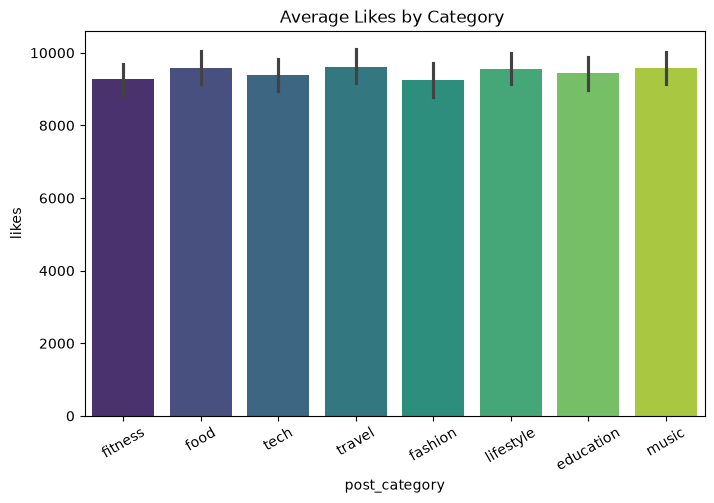

In [68]:
# 8. Bar plot: average likes by category
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="post_category", y="likes",estimator="mean", palette="viridis", hue="post_category")
plt.title("Average Likes by Category ")
plt.xticks(rotation=30)
plt.show()

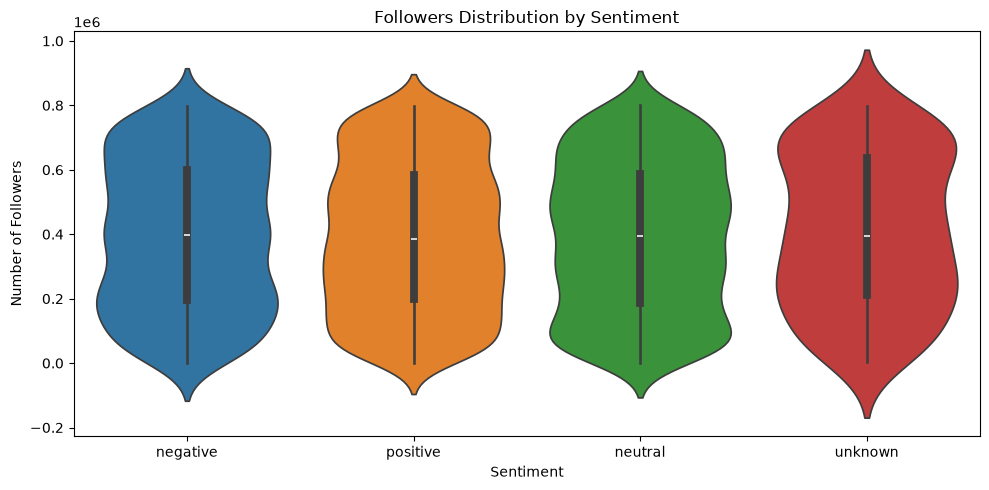

In [84]:
#Violin: followers vs sentiment

plt.figure(figsize=(10, 5))
sns.violinplot(data=df,x="sentiment",y="follower_count",hue="sentiment")
plt.title("Followers Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Followers")
plt.tight_layout()
plt.show()

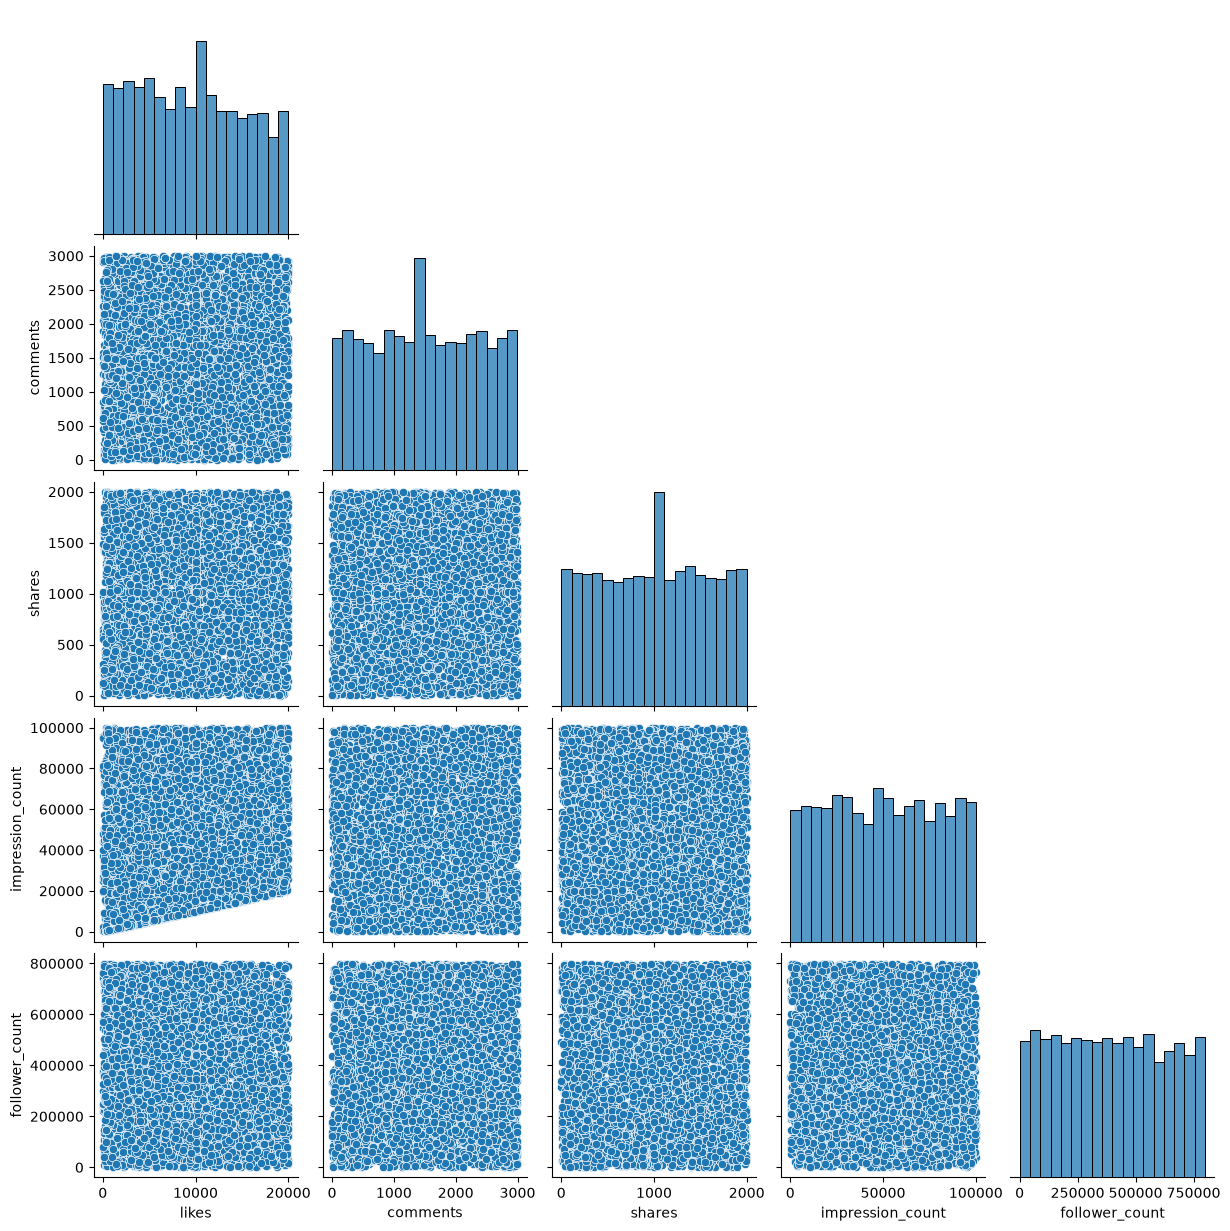

In [96]:
#Pair plot: numeric features
numeric_cols = ["likes","comments","shares","impression_count","follower_count"]
sns.pairplot(data=df[numeric_cols].dropna(),diag_kind="hist",corner=True)
plt.show()

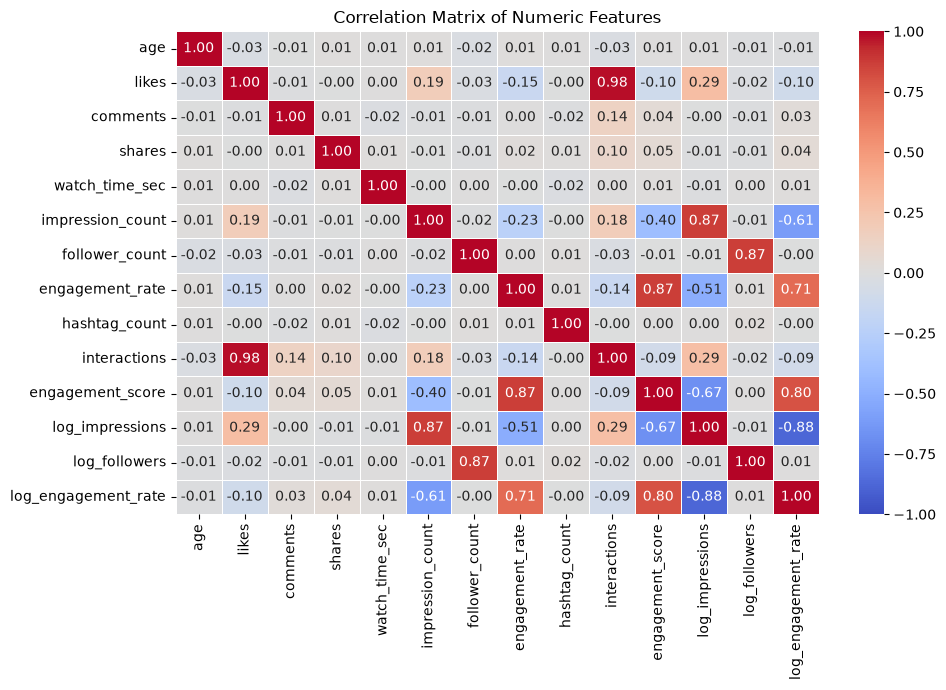

In [97]:
#Heatmap: correlation matrix
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5,vmin=-1,vmax=1)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

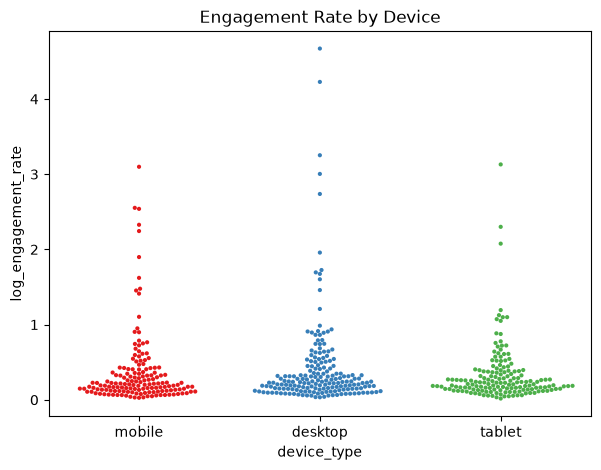

In [106]:
# 12. Swarm plot: engagement vs device (sample of 300 keeps the swarm readable)
fig, ax = plt.subplots(figsize=(7, 5))
sns.swarmplot(data=df.sample(500, random_state=2), x="device_type", y="log_engagement_rate", size=3, palette="Set1", ax=ax,hue="device_type")
ax.set_title("Engagement Rate by Device")
plt.show()

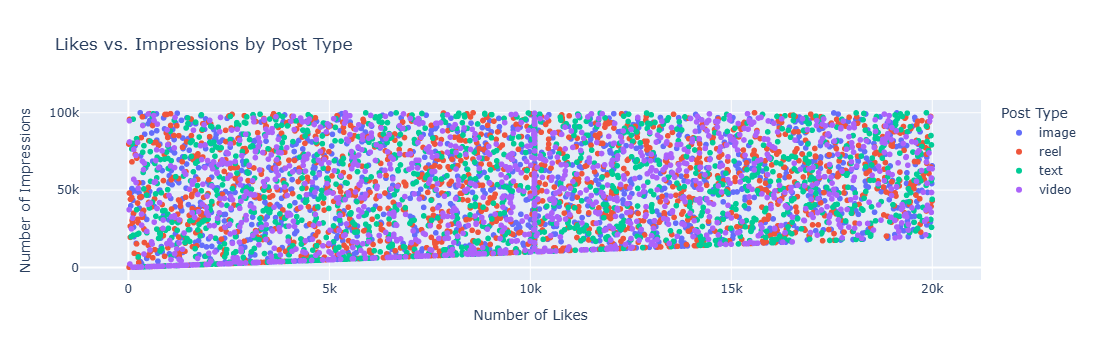

In [115]:
#Plotly (Interactive)

fig = px.scatter( df, x="likes",y="impression_count",color="post_type",hover_data=["comments", "shares"],title="Likes vs. Impressions by Post Type",
    labels={"likes": "Number of Likes","impression_count": "Number of Impressions","post_type": "Post Type"})
fig.show()

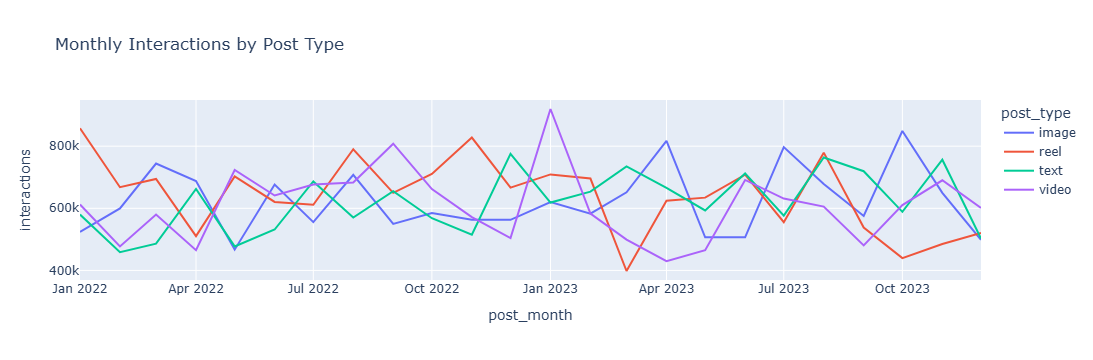

In [116]:
#Interactive line: monthly interactions by post type
m = df.groupby(["post_month", "post_type"])["interactions"].sum().reset_index()
px.line(m, x="post_month", y="interactions", color="post_type", title="Monthly Interactions by Post Type").show()

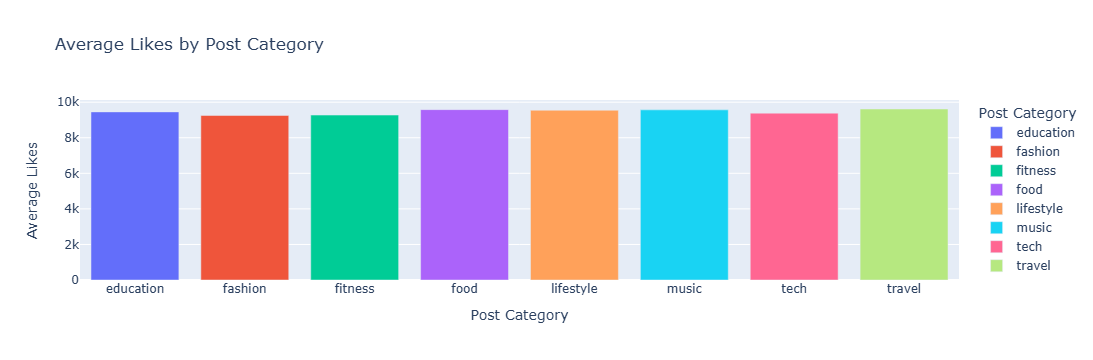

In [118]:
#Interactive bar chart — Average Likes by Post Category
avg_likes = (df.groupby("post_category", as_index=False)["likes"].mean().round(2))

fig = px.bar(avg_likes,x="post_category",y="likes",color="post_category",title="Average Likes by Post Category",
    labels={"post_category": "Post Category","likes": "Average Likes"})

fig.show()

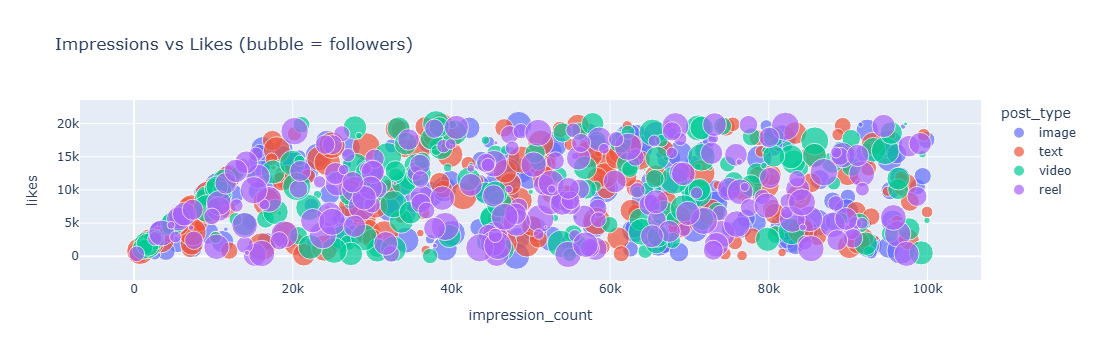

In [119]:
# 15. Interactive bubble chart: impressions vs likes, sized by followers
px.scatter(df.sample(800, random_state=3), x="impression_count", y="likes", size="follower_count",
           color="post_type", hover_data=["country", "post_category"], title="Impressions vs Likes (bubble = followers)").show()

In [120]:
print("PERFORMANCE")
print("Top post type:",
      post_type_performance["Average_Engagement"].idxmax())

print("Top content category:",
      category_performance["Average_Engagement"].idxmax())

print("Top country by engagement rate:",
      country_performance.idxmax())

print("\nUSER TRENDS")
print("Top age group:",
      age_group_performance.idxmax())

print("\nBEHAVIORAL INSIGHTS")
print("Best hour for impressions:",
      hourly_impressions.idxmax())

print("\nSENTIMENT ANALYSIS")
print("Best sentiment:",
      sentiment_performance["mean"].idxmax())

PERFORMANCE


NameError: name 'post_type_performance' is not defined